# Swiggy Sales Analysis 

**Tools:** Python, Pandas, NumPy, Matplotlib, Plotly  

# Project Summary

The **Swiggy Sales Analysis** project explores food-related records from **January 1 to August 31, 2025**, using **Python, Pandas, NumPy, Matplotlib, and Plotly**. The objective is to understand **recorded price patterns, food-category performance, city-level differences, time trends, and customer ratings**.

## 1. Import Libraries

In [1]:
# Pandas helps us load and analyze tabular data.
import pandas as pd

# NumPy helps us create the food category column.
import numpy as np

# Matplotlib creates static charts.
import matplotlib.pyplot as plt

# Plotly creates interactive charts.
import plotly.express as px

# Display more columns when inspecting the dataset.
pd.set_option("display.max_columns", None)

## 2. Load the Dataset

In [2]:
# Load the Excel file into a DataFrame named df.
df = pd.read_excel("Data/swiggy_data.xlsx")

# Show the first five records.
df.head()

,State,City,Order Date,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count
0,Karnataka,Bengaluru,2025-06-29,Anand Sweets & Savouries,Rajarajeshwari Nagar,Snack,Butter Murukku-200gm,133.9,4.0,0
1,Karnataka,Bengaluru,2025-04-03,Srinidhi Sagar Deluxe,Kengeri,Recommended,Badam Milk,52.0,4.5,25
2,Karnataka,Bengaluru,2025-01-15,Srinidhi Sagar Deluxe,Kengeri,Recommended,Chow Chow Bath,117.0,4.7,48
3,Karnataka,Bengaluru,2025-04-17,Srinidhi Sagar Deluxe,Kengeri,Recommended,Kesari Bath,65.0,4.6,65
4,Karnataka,Bengaluru,2025-03-13,Srinidhi Sagar Deluxe,Kengeri,Recommended,Mix Raitha,130.0,4.0,0


## 3. Understand the Dataset

In [3]:
# Show the number of rows and columns.
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 197430
Number of columns: 10


In [4]:
# Show column names, non-missing values, and data types.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 197430 entries, 0 to 197429
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   State            197430 non-null  str           
 1   City             197430 non-null  str           
 2   Order Date       197430 non-null  datetime64[us]
 3   Restaurant Name  197430 non-null  str           
 4   Location         197430 non-null  str           
 5   Category         197430 non-null  str           
 6   Dish Name        197430 non-null  str           
 7   Price (INR)      197430 non-null  float64       
 8   Rating           197430 non-null  float64       
 9   Rating Count     197430 non-null  int64         
dtypes: datetime64[us](1), float64(2), int64(1), str(6)
memory usage: 30.8 MB


In [5]:
# Show the first five rows.
display(df.head())

,State,City,Order Date,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count
0,Karnataka,Bengaluru,2025-06-29,Anand Sweets & Savouries,Rajarajeshwari Nagar,Snack,Butter Murukku-200gm,133.9,4.0,0
1,Karnataka,Bengaluru,2025-04-03,Srinidhi Sagar Deluxe,Kengeri,Recommended,Badam Milk,52.0,4.5,25
2,Karnataka,Bengaluru,2025-01-15,Srinidhi Sagar Deluxe,Kengeri,Recommended,Chow Chow Bath,117.0,4.7,48
3,Karnataka,Bengaluru,2025-04-17,Srinidhi Sagar Deluxe,Kengeri,Recommended,Kesari Bath,65.0,4.6,65
4,Karnataka,Bengaluru,2025-03-13,Srinidhi Sagar Deluxe,Kengeri,Recommended,Mix Raitha,130.0,4.0,0


In [6]:
# Show the last five rows.
display(df.tail())

,State,City,Order Date,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count
197425,Sikkim,Gangtok,2025-01-25,Mama's Kitchen,Gangtok,Momos,Soya cheese chilli momo ...,112.0,4.4,0
197426,Sikkim,Gangtok,2025-07-02,Mama's Kitchen,Gangtok,Momos,Kurkure momo fried ...,140.0,4.4,0
197427,Sikkim,Gangtok,2025-03-25,Mama's Kitchen,Gangtok,Momos,Chilli cheese momo,126.0,4.4,0
197428,Sikkim,Gangtok,2025-03-26,Mama's Kitchen,Gangtok,Momos,Veg Momos (8 Pc),85.0,4.4,0
197429,Sikkim,Gangtok,2025-03-27,Mama's Kitchen,Gangtok,Momos,Soya Momo,100.0,4.4,0


In [7]:
# Show summary statistics for numeric columns.
df.describe()

,Order Date,Price (INR),Rating,Rating Count
count,197430,197430.000000,197430.000000,197430.000000
mean,2025-05-01 19:41:20.996809,268.512920,4.341582,28.321805
min,2025-01-01 00:00:00,0.950000,1.500000,0.000000
25%,2025-03-01 00:00:00,139.000000,4.300000,0.000000
50%,2025-05-02 00:00:00,229.000000,4.400000,2.000000
75%,2025-07-01 00:00:00,329.000000,4.500000,15.000000
max,2025-08-31 00:00:00,8000.000000,5.000000,999.000000
std,NaN,219.338363,0.422585,87.542593


## 4. Check Data Quality

In [8]:
# Count missing values in each column.

missing_values = df.isnull().sum()
print("Missing values by column:")
display(missing_values)

Missing values by column:


State              0
City               0
Order Date         0
Restaurant Name    0
Location           0
Category           0
Dish Name          0
Price (INR)        0
Rating             0
Rating Count       0
dtype: int64

In [9]:
# Count exact duplicate occurrences
duplicate_count = df.duplicated().sum()

print("Exact duplicate occurrences:", duplicate_count)

Exact duplicate occurrences: 27


In [10]:
# Check data types.

display(df.dtypes)

State                         str
City                          str
Order Date         datetime64[us]
Restaurant Name               str
Location                      str
Category                      str
Dish Name                     str
Price (INR)               float64
Rating                    float64
Rating Count                int64
dtype: object

In [11]:
# Check for zero or negative prices
invalid_prices = df[df["Price (INR)"] <= 0]

print("Zero or negative prices:", len(invalid_prices))

display(invalid_prices)

Zero or negative prices: 0


,State,City,Order Date,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count


In [12]:
# Find ratings outside the expected 1-to-5 range
invalid_ratings = df[
    (df["Rating"] < 1) | (df["Rating"] > 5)
]

print("Invalid ratings:", len(invalid_ratings))

display(invalid_ratings)

Invalid ratings: 0


,State,City,Order Date,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count


In [13]:
# Make a working copy so the original DataFrame stays unchanged.
df = df.copy()

# Remove extra spaces from column names.
df.columns = df.columns.str.strip()

# Convert the order date column to datetime.
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

# Convert price, rating, and rating count to numeric values if needed.
df["Price (INR)"] = pd.to_numeric(df["Price (INR)"], errors="coerce")
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")
df["Rating Count"] = pd.to_numeric(df["Rating Count"], errors="coerce")

# Check how many dates or numeric values could not be converted.
print("Missing/invalid dates:", df["Order Date"].isna().sum())
print("Missing/invalid prices:", df["Price (INR)"].isna().sum())
print("Missing ratings:", df["Rating"].isna().sum())
print("Missing/invalid rating counts:", df["Rating Count"].isna().sum())

Missing/invalid dates: 0
Missing/invalid prices: 0
Missing ratings: 0
Missing/invalid rating counts: 0


## 5. Calculate Headline KPIs

In [14]:
# Sum the available price values. This is not confirmed revenue without data definitions.
total_recorded_price = df["Price (INR)"].sum()

# Calculate the average price per valid record.
average_price_per_record = df["Price (INR)"].mean()

# Calculate the average of available ratings.
average_rating = df["Rating"].mean()

# Sum the Rating Count field; validate what this field represents before interpreting it.
total_rating_count = df["Rating Count"].sum()

# Count rows in the dataset. This is record count, not necessarily unique orders.
total_records = len(df)

print("Total recorded price value (INR):", round(total_recorded_price, 2))
print("Average price per record (INR):", round(average_price_per_record, 2))
print("Average rating:", round(average_rating, 2))
print("Sum of Rating Count:", int(total_rating_count))
print("Total records:", total_records)

Total recorded price value (INR): 53012505.77
Average price per record (INR): 268.51
Average rating: 4.34
Sum of Rating Count: 5591574
Total records: 197430


## 6. Food Category Analysis

In [15]:
non_veg_keywords = [
    # Meat
    "chicken", "mutton", "lamb", "goat", "pork", "beef", "meat",

    # Seafood
    "fish", "prawn", "prawns", "shrimp", "crab", "lobster",
    "seafood", "squid", "octopus", "tuna", "salmon",

    # Egg
    "egg", "eggs", "omelette", "omelet",

    # Non-vegetarian dishes
    "biryani", "biriyani", "keema", "kheema",
    "kabab", "kebab", "tikka", "tandoori",
    "chilli chicken", "chicken 65", "chicken lollipop",
    "butter chicken", "chicken curry", "mutton curry",
    "fish curry", "fish fry", "chicken fry",
    "fried chicken", "chicken popcorn", "seekh",
    "reshmi", "shami", "egg curry", "egg bhurji",
    "egg roll", "egg dosa", "egg rice",
    "chicken manchurian", "chicken noodles",
    "chicken fried rice", "chicken burger", "chicken pizza",

    # Other non-vegetarian ingredients
    "ham", "bacon", "sausage", "salami",
    "pepperoni", "duck", "turkey",

    # Category labels
    "non-veg", "non veg", "nonvegetarian", "non-vegetarian"
]

df["Food Category"] = np.where(
df["Dish Name"]. str. lower().str.contains("|".join(non_veg_keywords), na=False),
"Non-Veg",
"Veg"
)

In [16]:
food_revenue = (
    df.groupby("Food Category")["Price (INR)"]
    .sum()
    .reset_index()
)

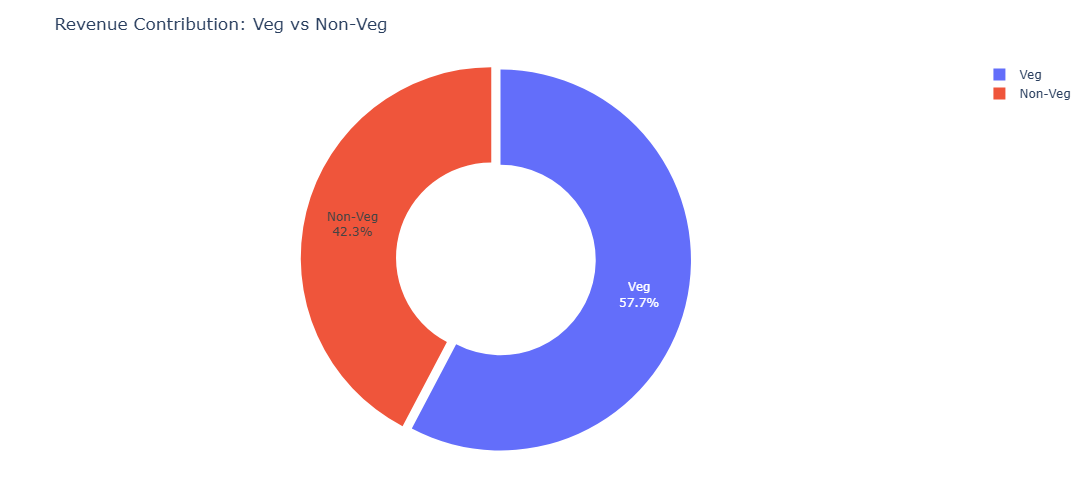

In [17]:
fig = px.pie(
    food_revenue,
    values="Price (INR)",
    names="Food Category",
    hole=0.5,
    title="Revenue Contribution: Veg vs Non-Veg",
)

fig. update_traces(
    textinfo="percent+label",
    pull=[0.05, 0]

)

fig. update_layout(
    height=500,
    margin=dict(t=60, b=40, l=40, r=40)
)

fig.show()

In [18]:
# Group records by food category and add the price values.
food_summary = (
    df.groupby("Food Category", as_index=False)
      .agg(
          Total_Recorded_Price=("Price (INR)", "sum"),
          Record_Count=("Dish Name", "size"),
          Average_Price_Per_Record=("Price (INR)", "mean")
      )
)

# Calculate each category's share of the total recorded price value.
food_summary["Price_Share_Percent"] = (
    food_summary["Total_Recorded_Price"] / food_summary["Total_Recorded_Price"].sum() * 100
)

display(food_summary.sort_values("Total_Recorded_Price", ascending=False))

,Food Category,Total_Recorded_Price,Record_Count,Average_Price_Per_Record,Price_Share_Percent
1,Veg,30592470.91,130995,233.539226,57.708027
0,Non-Veg,22420034.86,66435,337.473242,42.291973


### 6.2 Record count by food category

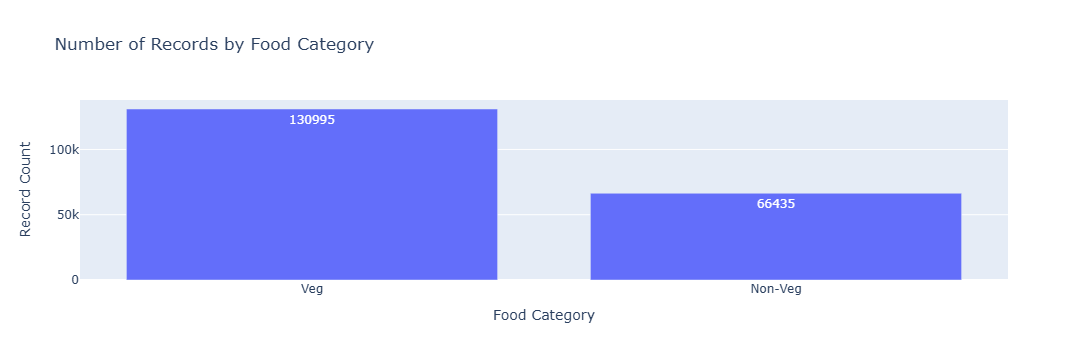

In [19]:
# Count the number of records in each food category.
category_records = df["Food Category"].value_counts().reset_index()
category_records.columns = ["Food Category", "Record Count"]

# Create a bar chart.
fig = px.bar(
    category_records,
    x="Food Category",
    y="Record Count",
    title="Number of Records by Food Category",
    text="Record Count"
)
fig.show()

### 6.3 Top dishes by record count

,Dish Name,Record_Count
0,Choco Lava Cake,303
1,Veg Fried Rice,243
2,Chicken Sausage,227
3,Paneer Butter Masala,226
4,Jeera Rice,219
5,Margherita Pizza,199
6,French Fries,194
7,Butter Naan,186
8,Margherita,184
9,Veggie Supreme,179


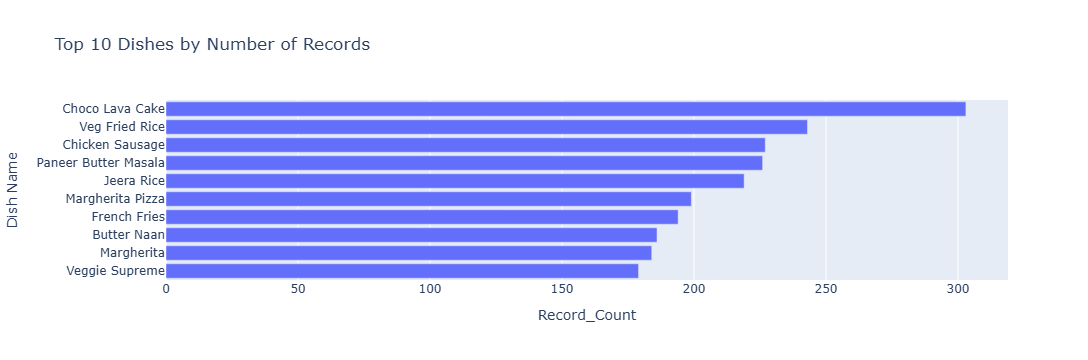

In [20]:
### 6.3 Top dishes by record count

# Count how often each dish appears in the dataset.
top_dishes = (
    df["Dish Name"]
      .value_counts()
      .head(10)
      .reset_index()
)

top_dishes.columns = ["Dish Name", "Record_Count"]

display(top_dishes)

# Plot the most frequently appearing dish names.
fig = px.bar(
    top_dishes.sort_values("Record_Count"),
    x="Record_Count",
    y="Dish Name",
    orientation="h",
    title="Top 10 Dishes by Number of Records"
)
fig.show()

## 7. State and City Analysis

### 7.1 Total recorded price value by state

In [21]:
# Add price values for each state and sort from highest to lowest.
state_summary = (
    df.groupby("State", as_index=False)["Price (INR)"]
      .sum()
      .rename(columns={"Price (INR)": "Total_Recorded_Price"})
      .sort_values("Total_Recorded_Price", ascending=False)
)

display(state_summary.head(10))

,State,Total_Recorded_Price
10,Karnataka,5456798.41
25,Uttar Pradesh,3117359.65
23,Telangana,3021711.62
13,Maharashtra,3015573.35
3,Delhi,2829180.60
5,Gujarat,2817836.02
19,Punjab,2809440.69
27,West Bengal,2662801.76
22,Tamil Nadu,2642594.63
20,Rajasthan,2502932.61


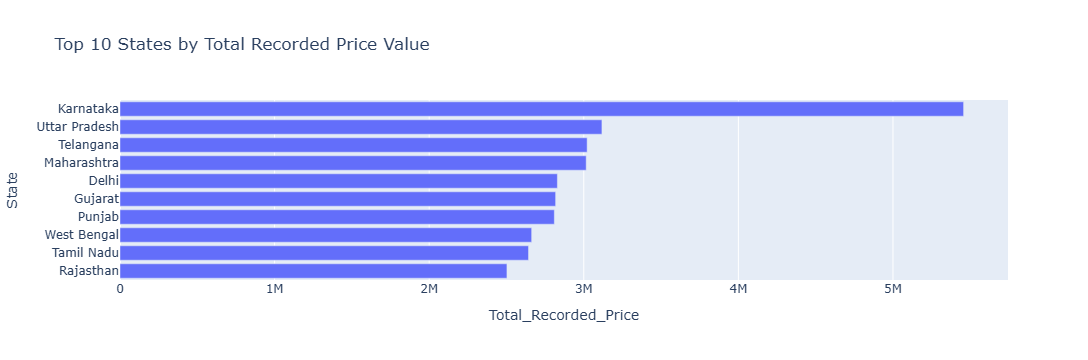

In [22]:
# Plot the top 10 states.
fig = px.bar(
    state_summary.head(10).sort_values("Total_Recorded_Price"),
    x="Total_Recorded_Price",
    y="State",
    orientation="h",
    title="Top 10 States by Total Recorded Price Value"
)
fig.show()

### 7.2 Top 5 cities by total recorded price value

In [23]:
# Add price values for each city and keep the top five.
city_summary = (
    df.groupby("City", as_index=False)["Price (INR)"]
      .sum()
      .rename(columns={"Price (INR)": "Total_Recorded_Price"})
      .nlargest(5, "Total_Recorded_Price")
      .sort_values("Total_Recorded_Price")
)

display(city_summary.sort_values("Total_Recorded_Price", ascending=False))

,City,Total_Recorded_Price
3,Bengaluru,5456798.41
18,Lucknow,3117359.65
11,Hyderabad,3021711.62
19,Mumbai,3015573.35
20,New Delhi,2829180.60


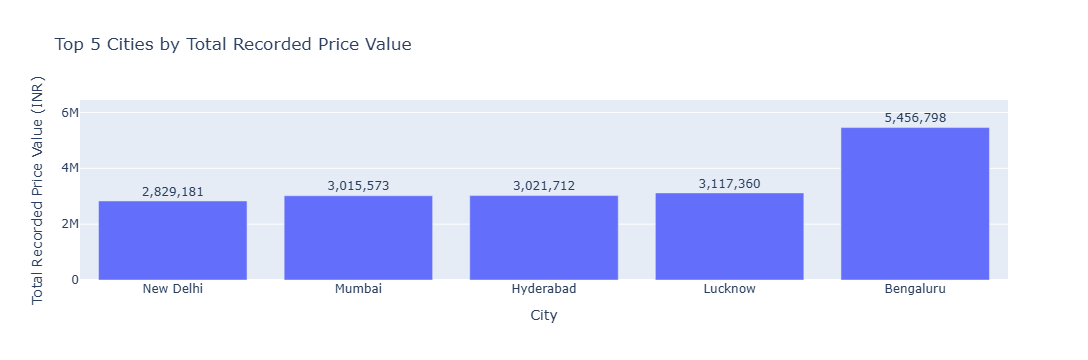

In [24]:
# Create a vertical column chart
fig = px.bar(
    city_summary,
    x="City",
    y="Total_Recorded_Price",
    title="Top 5 Cities by Total Recorded Price Value",
    text="Total_Recorded_Price"
)

fig.update_traces(texttemplate="%{text:,.0f}", textposition="outside")

fig.update_layout(
    xaxis_title="City",
    yaxis_title="Total Recorded Price Value (INR)"
)

fig.show()

### 7.3 compare city record count and average price

In [25]:
# Summarize each city using total price, number of records, and average price.
city_comparison = (
    df.groupby("City", as_index=False)
      .agg(
          Total_Recorded_Price=("Price (INR)", "sum"),
          Record_Count=("Price (INR)", "count"),
          Average_Price_Per_Record=("Price (INR)", "mean")
      )
      .sort_values("Total_Recorded_Price", ascending=False)
)

display(city_comparison.head(10))

,City,Total_Recorded_Price,Record_Count,Average_Price_Per_Record
3,Bengaluru,5456798.41,20077,271.793515
18,Lucknow,3117359.65,10192,305.863388
11,Hyderabad,3021711.62,10309,293.113941
19,Mumbai,3015573.35,10507,287.006124
20,New Delhi,2829180.60,10191,277.615602
1,Ahmedabad,2817836.02,10185,276.665294
5,Chandigarh,2809440.69,10065,279.129726
17,Kolkata,2662801.76,10046,265.060896
6,Chennai,2642594.63,10042,263.154215
14,Jaipur,2502932.61,10286,243.333911


## 8. Time Trend Analysis

### 8.1 Monthly trend

,YearMonth,Total_Recorded_Price
0,2025-01,6825186.03
1,2025-02,6269105.67
2,2025-03,6573530.07
3,2025-04,6594515.00
4,2025-05,6793558.40
5,2025-06,6514183.19
6,2025-07,6650965.51
7,2025-08,6791461.90


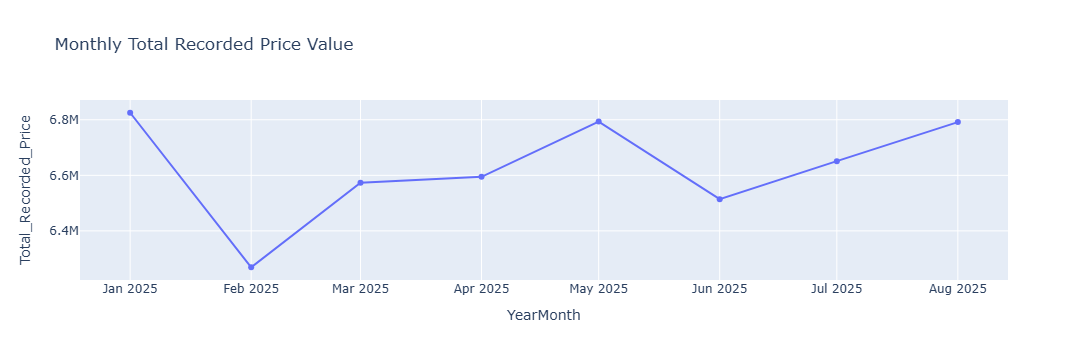

In [26]:
# Create a year-month column for grouping.
df["YearMonth"] = df["Order Date"].dt.to_period("M").astype(str)

# Calculate the total recorded price value for each month.
monthly_summary = (
    df.groupby("YearMonth", as_index=False)["Price (INR)"]
      .sum()
      .rename(columns={"Price (INR)": "Total_Recorded_Price"})
      .sort_values("YearMonth")
)

display(monthly_summary)

# Plot monthly totals over time.
fig = px.line(
    monthly_summary,
    x="YearMonth",
    y="Total_Recorded_Price",
    markers=True,
    title="Monthly Total Recorded Price Value"
)
fig.show()

### 8.2 Day-of-week trend

In [27]:
# Get the weekday name for each order date.
df["DayName"] = df["Order Date"].dt.day_name()

# Define the weekday order so the chart runs Monday to Sunday.
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Calculate total recorded price value for each weekday.
daily_summary = (
    df.groupby("DayName")["Price (INR)"]
      .sum()
      .reindex(weekday_order)
      .reset_index()
      .rename(columns={"Price (INR)": "Total_Recorded_Price"})
)

display(daily_summary)

,DayName,Total_Recorded_Price
0,Monday,7445437.01
1,Tuesday,7359414.01
2,Wednesday,7542103.06
3,Thursday,7664619.49
4,Friday,7579992.78
5,Saturday,7782935.40
6,Sunday,7638004.02


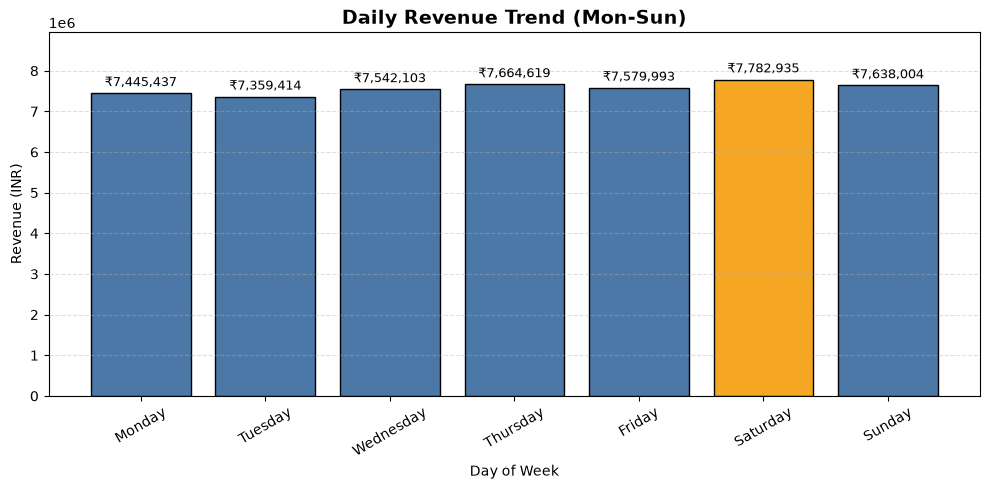

In [28]:
df["DayName"] = pd.to_datetime(df["Order Date"]).dt.day_name()

daily_revenue = (
    df.groupby("DayName")["Price (INR)"]
      .sum()
      .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
)

# Highlight the best day, others in a softer colour
colors = ["#F5A623" if v == daily_revenue.max() else "#4C78A8" for v in daily_revenue.values]

plt.figure(figsize=(10, 5))
bars = plt.bar(daily_revenue.index, daily_revenue.values, color=colors, edgecolor="black")

# Value labels on top of each bar
plt.bar_label(bars, labels=[f"₹{v:,.0f}" for v in daily_revenue.values], padding=3, fontsize=9)

plt.title("Daily Revenue Trend (Mon-Sun)", fontsize=14, fontweight="bold")
plt.xlabel("Day of Week")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=30)
plt.ylim(0, daily_revenue.max() * 1.15)  # extra headroom so labels don't get cut off
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

### 8.3 Quarterly performance

In [29]:
# Extract the calendar quarter from each order date.
df["Quarter"] = df["Order Date"].dt.to_period("Q").astype(str)

# Calculate quarterly price total, average rating, and record count.
quarterly_summary = (
    df.groupby("Quarter", as_index=False)
      .agg(
          Total_Recorded_Price=("Price (INR)", "sum"),
          Average_Rating=("Rating", "mean"),
          Record_Count=("Order Date", "count")
      )
      .sort_values("Quarter")
)

display(quarterly_summary)

,Quarter,Total_Recorded_Price,Average_Rating,Record_Count
0,2025Q1,19667821.77,4.342643,73096
1,2025Q2,19902256.59,4.340011,74163
2,2025Q3,13442427.41,4.342359,50171


## 9. Customer Rating Analysis

### 9.1 Rating distribution

,Rating,Record_Count
0,1.5,64
1,1.6,30
2,1.7,25
3,1.8,55
4,1.9,50
5,2.0,247
6,2.1,161
7,2.2,209
8,2.3,227
9,2.4,234


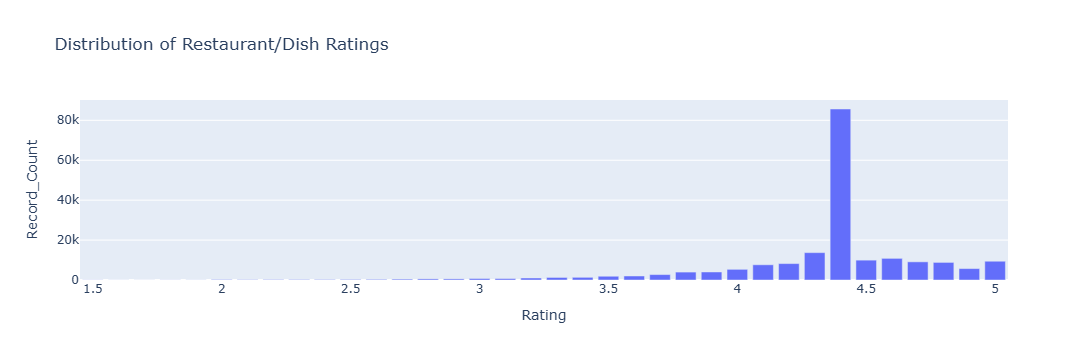

In [30]:
# Count how many records have each rating value.
rating_counts = (
    df["Rating"]
      .value_counts()
      .sort_index()
      .reset_index()
)
rating_counts.columns = ["Rating", "Record_Count"]

display(rating_counts)

# Plot the rating distribution.
fig = px.bar(
    rating_counts,
    x="Rating",
    y="Record_Count",
    title="Distribution of Restaurant/Dish Ratings"
)
fig.show()

### 9.2 Average rating by food category

In [31]:
# Calculate average rating and number of available ratings by food category.
rating_by_category = (
    df.groupby("Food Category", as_index=False)
      .agg(
          Average_Rating=("Rating", "mean"),
          Rating_Record_Count=("Rating", "count")
      )
)

display(rating_by_category)

,Food Category,Average_Rating,Rating_Record_Count
0,Non-Veg,4.322133,66435
1,Veg,4.351445,130995


### 9.3 Lowest-rated restaurants with enough records

In [32]:
# Calculate each restaurant's average rating and number of rating records.
restaurant_ratings = (
    df.groupby("Restaurant Name", as_index=False)
      .agg(
          Average_Rating=("Rating", "mean"),
          Rating_Record_Count=("Rating", "count")
      )
)

# Keep restaurants with at least 20 available rating records.
restaurant_ratings_filtered = restaurant_ratings[
    restaurant_ratings["Rating_Record_Count"] >= 20
]

# Show the lowest average ratings first.
display(
    restaurant_ratings_filtered
    .sort_values("Average_Rating")
    .head(10)
)

,Restaurant Name,Average_Rating,Rating_Record_Count
144,Cafe 99,3.685897,78
259,Dreams Cafe,3.721212,66
412,Jai Krishna Vaishno Dhaba,3.742609,115
708,Roll Corner,3.778409,88
401,Idly Dosa for You,3.785294,68
385,House of parathas,3.827027,37
229,Dawat-E-Khas Sweets & Snacks,3.850704,71
928,Truck Wala Dhaba,3.868493,73
290,Food Lovers Restaurant,3.871503,193
511,Mahawar Baker's & Sweets,3.880723,166



# Key Insights

1. **Overall performance:** The total recorded price value is ₹5.30 crore, with an average price of ₹268.51 per record across 197,430 records.

2. **Food-category performance:** Veg contributes ₹3.06 crore (57.71%) of the total recorded price value, while Non-Veg contributes ₹2.24 crore (42.29%). Non-Veg has a higher average price per record (₹337.47) than Veg (₹233.54).

3. **Popular dishes:** Choco Lava Cake appears most frequently, with 303 records, followed by Veg Fried Rice (243) and Chicken Sausage (227).

4. **Geographic performance:** Karnataka has the highest total recorded price value among states, at ₹54.57 lakh. Bengaluru leads the city analysis with the same total.

5. **City-level differences:** Bengaluru has 20,077 records and an average price of ₹271.79 per record. Lucknow has fewer records (10,192) but a higher average price of ₹305.86 per record.

6. **Monthly and weekday trends:** January has the highest monthly total, at ₹68.25 lakh, while February has the lowest, at ₹62.69 lakh. Saturday has the highest weekday total (₹77.83 lakh), while Tuesday has the lowest (₹73.59 lakh).

7. **Quarterly performance:** Q2 has the highest total recorded price value at ₹1.99 crore, slightly above Q1's ₹1.97 crore. Q3 is incomplete because the dataset ends in August.

8. **Customer ratings:** The overall average rating is approximately 4.34 out of 5. Veg has a slightly higher average rating (4.35) than Non-Veg (4.32).

9. **Restaurants needing attention:** Cafe 99 has the lowest average rating among the restaurants with at least 20 rating records, at 3.69 across 78 records.


# Recommendations

1. **Food categories:** Maintain the strong presence of Veg dishes while investigating opportunities to promote Non-Veg dishes, which have a higher average price per record.

2. **Popular dishes:** Review frequently appearing dishes such as Choco Lava Cake and Veg Fried Rice to understand their contribution to overall performance and whether they merit further promotion.

3. **Geographic performance:** Investigate what contributes to Bengaluru's high total and compare its dish mix and price distribution with Lucknow and Hyderabad.

4. **Time trends:** Compare monthly and weekday patterns to identify periods with relatively higher recorded price totals. Avoid making strong seasonal conclusions from a single eight-month period.

5. **Customer ratings:** Review customer feedback for lower-rated restaurants, starting with Cafe 99 and Dreams Cafe, to identify potential areas for improvement.

6. **Ongoing monitoring:** Track recorded price totals, record counts, average prices, and ratings together to avoid relying on any single measure when evaluating performance.

# Conclusion

The **Swiggy Sales Analysis** project demonstrates how **Python-based data analysis** can turn a large dataset into useful business insights. The analysis identified differences between **Veg and Non-Veg price patterns**, highlighted leading states and cities, revealed monthly and weekday trends, and identified restaurants that may benefit from further review.

The findings suggest that **Veg contributes the largest share of the total recorded price value**, while **Non-Veg has a higher average price per record**. **Bengaluru** leads in aggregate recorded price value, and overall ratings remain high at approximately **4.34 out of 5**.

This project strengthened practical skills in **data cleaning, data validation, grouping and aggregation, KPI calculation, trend analysis, data visualization, and business interpretation**.